# Analysis 4: Natural Disaster Pattern Analysis

## Objective
To identify meaningful patterns and relationships between natural disaster frequency, severity, affected populations, and economic losses.

## Research Questions
1. Which disaster types are associated with the highest mortality?
2. Which disaster types affect the largest number of people?
3. Which disaster types cause the greatest economic losses?
4. Are frequently occurring disasters necessarily the most destructive?
5. Are there relationships between deaths, affected population, and economic damage?

## Methodology
- Compare disaster types using event-level records.
- Calculate average impacts per reported event.
- Examine relationships between different impact measures.
- Identify disaster types with unusually high average impacts.
- Consider missing data and reporting coverage when interpreting results.

## Limitations
- Missing impact values are not treated as zero.
- Economic damage is reported for fewer events than deaths or affected population.
- Extreme disasters can influence averages significantly.
- Correlation does not establish causation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

ROOT = Path.cwd()

if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"
OUTPUT_DIR = ROOT / "analysis" / "outputs"
VIS_DIR = ROOT / "visualizations" / "patterns"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

events = pd.read_csv(
    DATA_DIR / "natural_disaster_events.csv",
    encoding="utf-8-sig"
)

print("Dataset shape:", events.shape)
print("Disaster types:", events["Disaster Type"].nunique())
events.head()

Dataset shape: (15727, 35)
Disaster types: 15


,Event ID,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,Classification Key,Start Year,Start Month,Start Day,Start Date,...,No. Homeless,No. Homeless Reported Country Impacts,Total Affected,Total Affected Reported Country Impacts,"Total Damage, Adjusted ('000 US$)","Total Damage, Adjusted ('000 US$) Reported Country Impacts","Total Damage, Adjusted (million US$)","Total Damage, Adjusted (million US$) Reported Country Impacts",Magnitude,Magnitude Reported Country Impacts
0,1987-0326,Natural,Hydrological,Flood,Riverine flood,nat-hyd-flo-riv,1987,10.0,31.0,1987-10-31,...,NaN,0,26000.0,1,87835.0,1,87.835,1,NaN,0
1,1987-0590,Natural,Meteorological,Storm,Tropical cyclone,nat-met-sto-tro,1987,11.0,21.0,1987-11-21,...,200.0,1,203.0,1,17000.0,1,17.000,1,148.0,1
2,1988-0312,Natural,Meteorological,Storm,Tropical cyclone,nat-met-sto-tro,1988,7.0,16.0,1988-07-16,...,21235.0,1,117508.0,2,766391.0,2,766.391,2,430.0,2
3,1988-0424,Natural,Meteorological,Storm,Tropical cyclone,nat-met-sto-tro,1988,8.0,11.0,1988-08-11,...,NaN,0,870000.0,1,251236.0,2,251.236,2,740.0,4
4,1989-0447,Natural,Meteorological,Storm,Tropical cyclone,nat-met-sto-tro,1989,6.0,24.0,1989-06-24,...,NaN,0,NaN,0,1298506.0,1,1298.506,1,85.0,1


In [2]:
impact_columns = [
    "Total Deaths",
    "Total Affected",
    "Total Damage, Adjusted (million US$)"
]

for col in impact_columns:
    events[col] = pd.to_numeric(events[col], errors="coerce")

print("Missing values in impact columns:")
print(events[impact_columns].isnull().sum())

Missing values in impact columns:
Total Deaths                             4072
Total Affected                           3361
Total Damage, Adjusted (million US$)    10476
dtype: int64


In [ ]:
#DISASTER TYPES ACROSS IMPACTS (IMP)

In [3]:
pattern_summary = (
    events.groupby("Disaster Type")
    .agg(
        Unique_Events=("Event ID", "nunique"),

        Death_Reported=("Total Deaths", "count"),
        Total_Deaths=("Total Deaths", lambda x: x.sum(min_count=1)),
        Average_Deaths=("Total Deaths", "mean"),
        Median_Deaths=("Total Deaths", "median"),

        Affected_Reported=("Total Affected", "count"),
        Total_Affected=("Total Affected", lambda x: x.sum(min_count=1)),
        Average_Affected=("Total Affected", "mean"),
        Median_Affected=("Total Affected", "median"),

        Damage_Reported=("Total Damage, Adjusted (million US$)", "count"),
        Total_Damage=("Total Damage, Adjusted (million US$)", lambda x: x.sum(min_count=1)),
        Average_Damage=("Total Damage, Adjusted (million US$)", "mean"),
        Median_Damage=("Total Damage, Adjusted (million US$)", "median")
    )
    .reset_index()
)

pattern_summary["Death Coverage (%)"] = (
    pattern_summary["Death_Reported"] / pattern_summary["Unique_Events"] * 100
)

pattern_summary["Affected Coverage (%)"] = (
    pattern_summary["Affected_Reported"] / pattern_summary["Unique_Events"] * 100
)

pattern_summary["Damage Coverage (%)"] = (
    pattern_summary["Damage_Reported"] / pattern_summary["Unique_Events"] * 100
)

pattern_summary.head(15)

,Disaster Type,Unique_Events,Death_Reported,Total_Deaths,Average_Deaths,Median_Deaths,Affected_Reported,Total_Affected,Average_Affected,Median_Affected,Damage_Reported,Total_Damage,Average_Damage,Median_Damage,Death Coverage (%),Affected Coverage (%),Damage Coverage (%)
0,Animal incident,1,1,12.0,12.000000,12.0,1,5.000000e+00,5.000000e+00,5.0,0,NaN,NaN,NaN,100.000000,100.000000,0.000000
1,Drought,647,67,11734353.0,175139.597015,200.0,477,3.028731e+09,6.349540e+06,900000.0,205,456883.972,2228.702302,630.4010,10.355487,73.724884,31.684699
2,Earthquake,1573,1190,2440922.0,2051.194958,19.0,1325,2.548584e+08,1.923459e+05,4500.0,626,1803517.195,2881.017883,121.2690,75.651621,84.233948,39.796567
3,Epidemic,1447,1243,9629942.0,7747.338697,46.0,1257,5.086409e+07,4.046467e+04,1000.0,1,0.061,0.061000,0.0610,85.901866,86.869385,0.069109
4,Extreme temperature,433,364,397964.0,1093.307692,62.0,181,1.414168e+08,7.813080e+05,5460.0,60,143465.781,2391.096350,585.8460,84.064665,41.801386,13.856813
5,Flood,5814,4343,7030614.0,1618.838130,17.0,5103,4.111435e+09,8.056899e+05,12000.0,1927,1906588.840,989.407805,100.3750,74.699002,87.770898,33.144135
6,Fog,1,1,4000.0,4000.000000,4000.0,0,NaN,NaN,NaN,0,NaN,NaN,NaN,100.000000,0.000000,0.000000
7,Glacial lake outburst flood,7,6,478.0,79.666667,27.0,4,9.414400e+04,2.353600e+04,2860.0,2,749.504,374.752000,374.7520,85.714286,57.142857,28.571429
8,Impact,1,0,NaN,NaN,NaN,1,3.014910e+05,3.014910e+05,301491.0,1,45.605,45.605000,45.6050,0.000000,100.000000,100.000000
9,Infestation,78,0,NaN,NaN,NaN,5,3.202200e+06,6.404400e+05,400000.0,4,454.451,113.612750,113.3715,0.000000,6.410256,5.128205


In [4]:
#HIGHEST

In [13]:
top_death_types = (
    pattern_summary
    .dropna(subset=["Average_Deaths"])
    .sort_values("Average_Deaths", ascending=False)
)

display(
    top_death_types[
        ["Disaster Type", "Unique_Events", "Death_Reported",
         "Average_Deaths", "Median_Deaths", "Death Coverage (%)"]
    ].head(10)
)

top_affected_types = (
    pattern_summary
    .dropna(subset=["Average_Affected"])
    .sort_values("Average_Affected", ascending=False)
)

display(
    top_affected_types[
        ["Disaster Type", "Unique_Events", "Affected_Reported",
         "Average_Affected", "Median_Affected", "Affected Coverage (%)"]
    ].head(10)
)

top_damage_types = (
    pattern_summary
    .dropna(subset=["Average_Damage"])
    .sort_values("Average_Damage", ascending=False)
)

display(
    top_damage_types[
        ["Disaster Type", "Unique_Events", "Damage_Reported",
         "Average_Damage", "Median_Damage", "Damage Coverage (%)"]
    ].head(10)
)


,Disaster Type,Unique_Events,Death_Reported,Average_Deaths,Median_Deaths,Death Coverage (%)
1,Drought,647,67,175139.597015,200.0,10.355487
3,Epidemic,1447,1243,7747.338697,46.0,85.901866
6,Fog,1,1,4000.000000,4000.0,100.000000
2,Earthquake,1573,1190,2051.194958,19.0,75.651621
5,Flood,5814,4343,1618.838130,17.0,74.699002
4,Extreme temperature,433,364,1093.307692,62.0,84.064665
13,Volcanic activity,277,96,905.677083,37.0,34.657040
12,Storm,4026,3219,446.086362,17.0,79.955291
10,Mass movement (dry),47,45,101.400000,40.0,95.744681
11,Mass movement (wet),867,830,86.402410,26.0,95.732411


,Disaster Type,Unique_Events,Affected_Reported,Average_Affected,Median_Affected,Affected Coverage (%)
1,Drought,647,477,6.349540e+06,900000.0,73.724884
5,Flood,5814,5103,8.056899e+05,12000.0,87.770898
4,Extreme temperature,433,181,7.813080e+05,5460.0,41.801386
9,Infestation,78,5,6.404400e+05,400000.0,6.410256
12,Storm,4026,2891,4.932487e+05,6631.0,71.808246
8,Impact,1,1,3.014910e+05,301491.0,100.000000
2,Earthquake,1573,1325,1.923459e+05,4500.0,84.233948
14,Wildfire,508,362,5.258814e+04,1082.0,71.259843
13,Volcanic activity,277,232,4.639666e+04,6944.0,83.754513
3,Epidemic,1447,1257,4.046467e+04,1000.0,86.869385


,Disaster Type,Unique_Events,Damage_Reported,Average_Damage,Median_Damage,Damage Coverage (%)
2,Earthquake,1573,626,2881.017883,121.2690,39.796567
4,Extreme temperature,433,60,2391.096350,585.8460,13.856813
1,Drought,647,205,2228.702302,630.4010,31.684699
12,Storm,4026,2096,1667.400677,223.9175,52.061600
14,Wildfire,508,189,1440.768841,219.0470,37.204724
5,Flood,5814,1927,989.407805,100.3750,33.144135
10,Mass movement (dry),47,3,714.145667,11.0560,6.382979
7,Glacial lake outburst flood,7,2,374.752000,374.7520,28.571429
13,Volcanic activity,277,46,342.002761,92.3010,16.606498
11,Mass movement (wet),867,91,261.275505,43.1190,10.495963


In [9]:
#AVERAGE

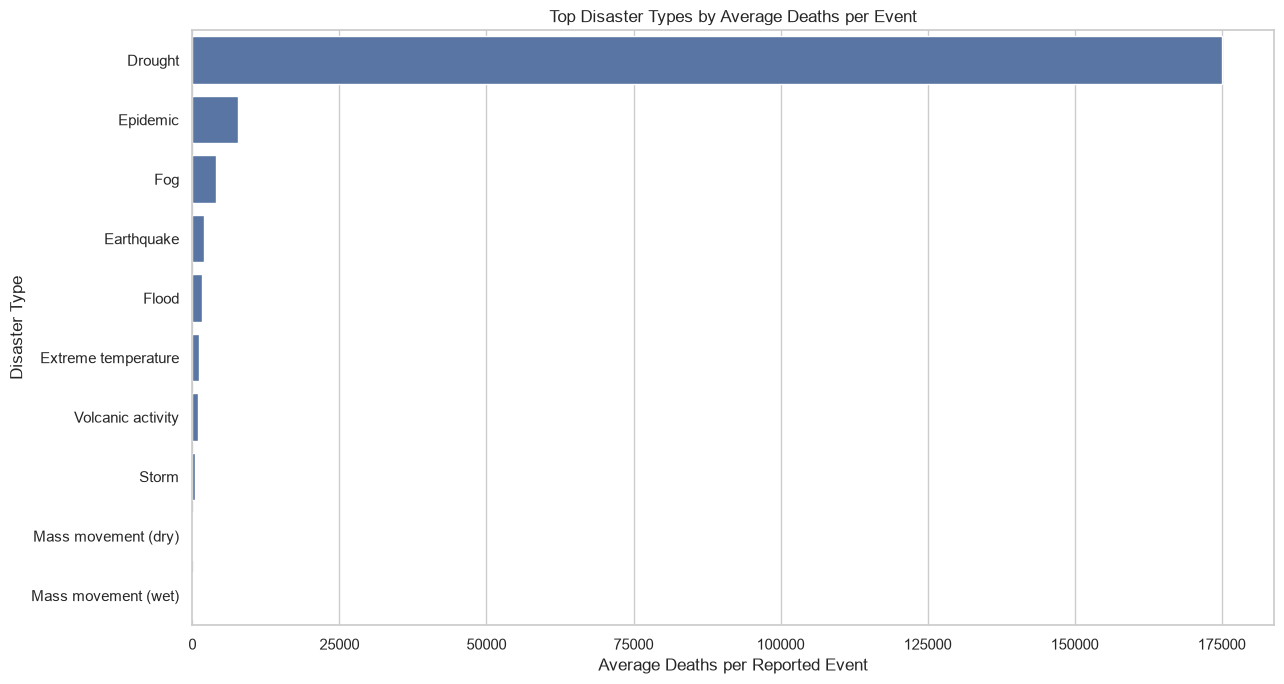

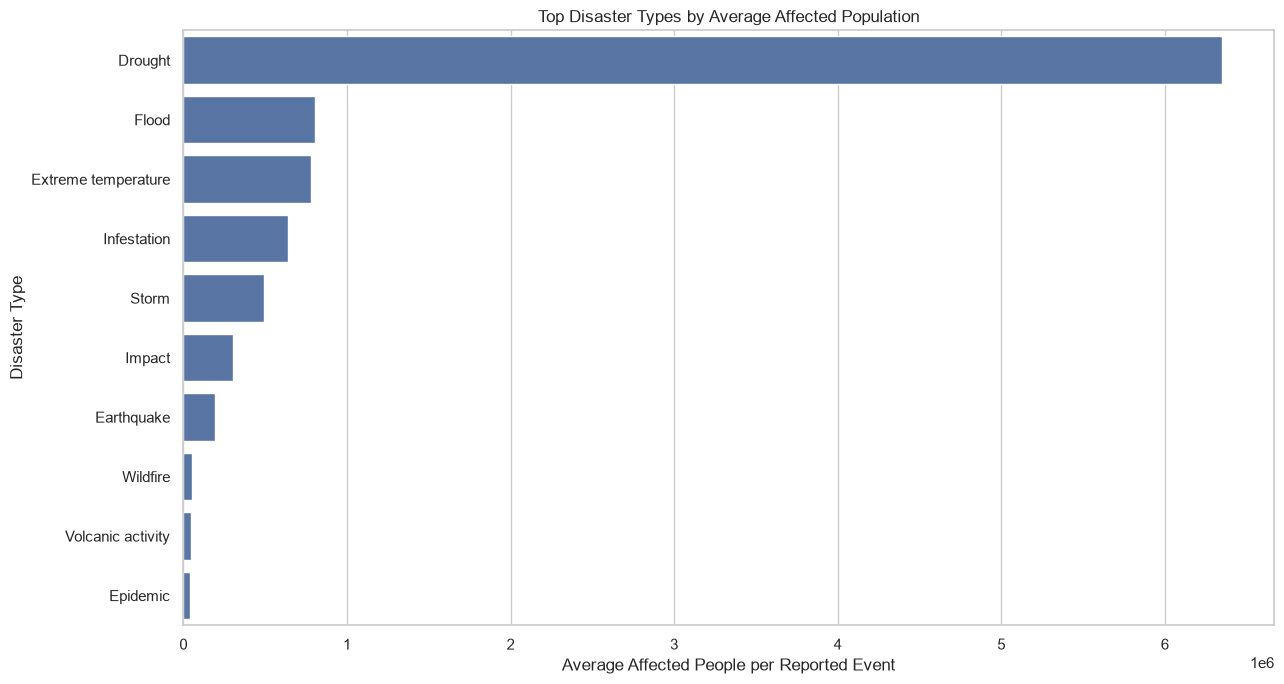

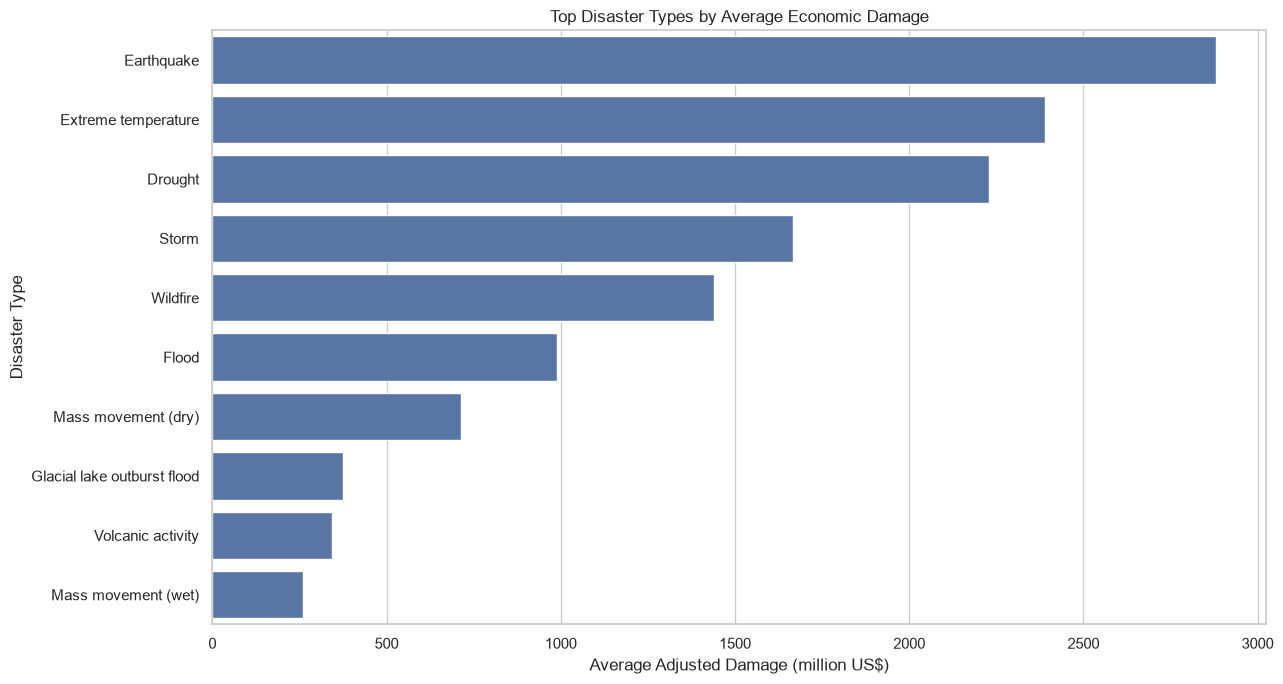

In [14]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_death_types.head(10),
    x="Average_Deaths",
    y="Disaster Type"
)

plt.title("Top Disaster Types by Average Deaths per Event")
plt.xlabel("Average Deaths per Reported Event")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "01_average_deaths_by_type.png", dpi=300)
plt.show()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_affected_types.head(10),
    x="Average_Affected",
    y="Disaster Type"
)

plt.title("Top Disaster Types by Average Affected Population")
plt.xlabel("Average Affected People per Reported Event")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "02_average_affected_by_type.png", dpi=300)
plt.show()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_damage_types.head(10),
    x="Average_Damage",
    y="Disaster Type"
)

plt.title("Top Disaster Types by Average Economic Damage")
plt.xlabel("Average Adjusted Damage (million US$)")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "03_average_damage_by_type.png", dpi=300)
plt.show()

In [15]:
correlation_data = events[
    ["Total Deaths", "Total Affected",
     "Total Damage, Adjusted (million US$)"]
].copy()

correlation_matrix = correlation_data.corr(method="spearman")

print(correlation_matrix)

                                      Total Deaths  Total Affected  \
Total Deaths                              1.000000        0.349609   
Total Affected                            0.349609        1.000000   
Total Damage, Adjusted (million US$)      0.244508        0.232650   

                                      Total Damage, Adjusted (million US$)  
Total Deaths                                                      0.244508  
Total Affected                                                    0.232650  
Total Damage, Adjusted (million US$)                              1.000000  


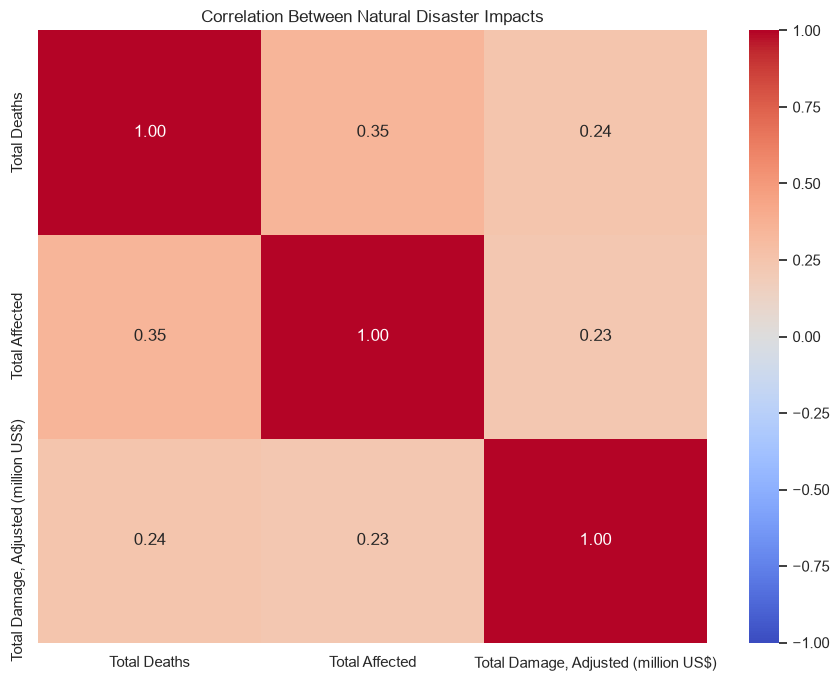

In [16]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Natural Disaster Impacts")
plt.tight_layout()

plt.savefig(VIS_DIR / "04_impact_correlation_heatmap.png", dpi=300)
plt.show()

In [17]:
frequency_impact = pattern_summary[
    ["Disaster Type", "Unique_Events", "Average_Deaths",
     "Average_Affected", "Average_Damage"]
].copy()

display(frequency_impact.sort_values("Unique_Events", ascending=False))

,Disaster Type,Unique_Events,Average_Deaths,Average_Affected,Average_Damage
5,Flood,5814,1618.838130,8.056899e+05,989.407805
12,Storm,4026,446.086362,4.932487e+05,1667.400677
2,Earthquake,1573,2051.194958,1.923459e+05,2881.017883
3,Epidemic,1447,7747.338697,4.046467e+04,0.061000
11,Mass movement (wet),867,86.402410,3.608815e+04,261.275505
1,Drought,647,175139.597015,6.349540e+06,2228.702302
14,Wildfire,508,21.024000,5.258814e+04,1440.768841
4,Extreme temperature,433,1093.307692,7.813080e+05,2391.096350
13,Volcanic activity,277,905.677083,4.639666e+04,342.002761
9,Infestation,78,NaN,6.404400e+05,113.612750


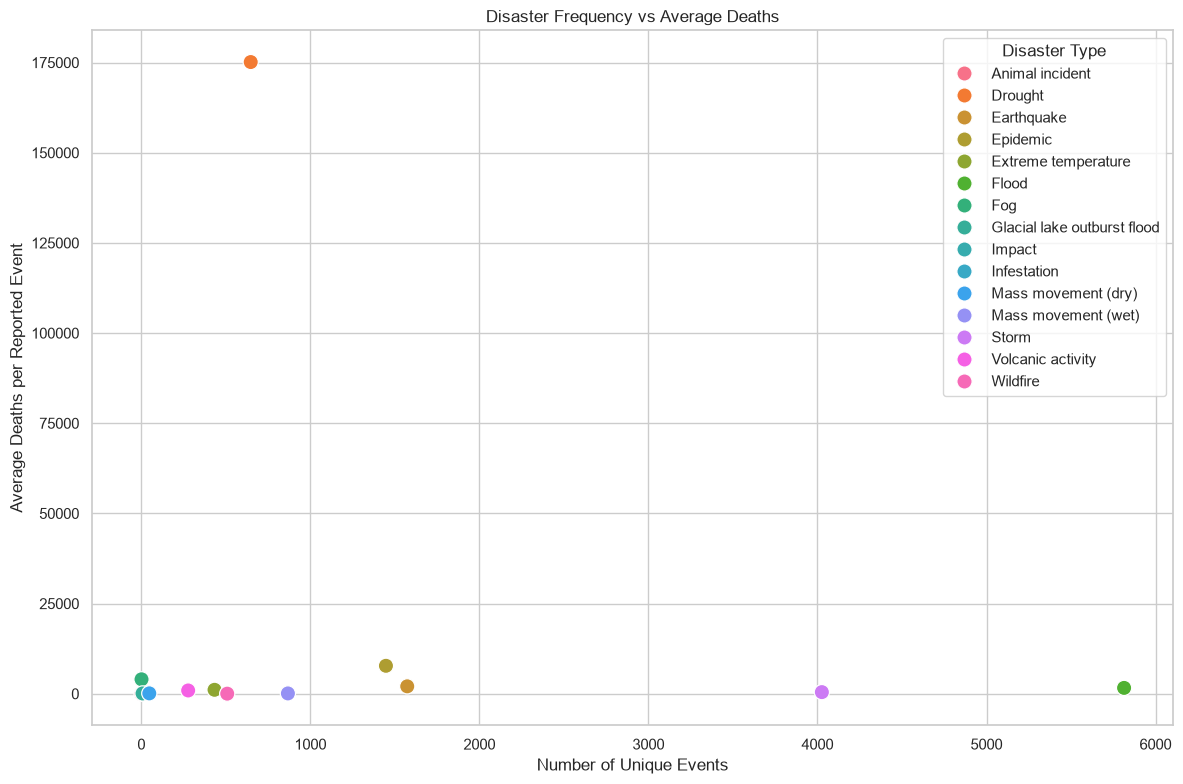

In [18]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=frequency_impact,
    x="Unique_Events",
    y="Average_Deaths",
    hue="Disaster Type",
    s=120
)

plt.title("Disaster Frequency vs Average Deaths")
plt.xlabel("Number of Unique Events")
plt.ylabel("Average Deaths per Reported Event")
plt.tight_layout()

plt.savefig(VIS_DIR / "05_frequency_vs_average_deaths.png", dpi=300)
plt.show()

In [19]:
pattern_summary.to_csv(
    OUTPUT_DIR / "disaster_pattern_summary.csv",
    index=False
)

frequency_impact.to_csv(
    OUTPUT_DIR / "frequency_vs_destructiveness.csv",
    index=False
)

correlation_matrix.to_csv(
    OUTPUT_DIR / "impact_correlation_matrix.csv"
)

print("Pattern analysis outputs saved successfully!")

Pattern analysis outputs saved successfully!
